# Three-band model of transition metal dichalcogenides
Let us see how to build a monolayer of a transition metal dichalcogenide (TMD) MX$_2$, with
`specialhamiltonian.three_band_tmdc()`. The states close to the gap are made of the
$d_{z^2}$, $d_{xy}$ and $d_{x^2-y^2}$ orbitals of the metal atom on a triangular lattice. The
hoppings up to the third neighbors and the spin-orbit coupling $\frac{\lambda}{2}L_z s_z$ were
fitted to first-principles bands by Liu et al. for MoS$_2$, WS$_2$, MoSe$_2$, WSe$_2$,
MoTe$_2$ and WTe$_2$. Energies are in eV and lengths in Å.
### Import the necessary libraries

In [1]:
# Add the root path of the pyqula library
import os ; import sys
sys.path.append(os.getcwd()+"/../../../src")

import numpy as np
import matplotlib.pyplot as plt
from pyqula import specialhamiltonian

### Band structures and spin-valley locking
We compute the bands of four TMDs, colored by the spin $\langle S_z\rangle$ of each state. The
path goes through $\Gamma$, K, M, K' and back to $\Gamma$.

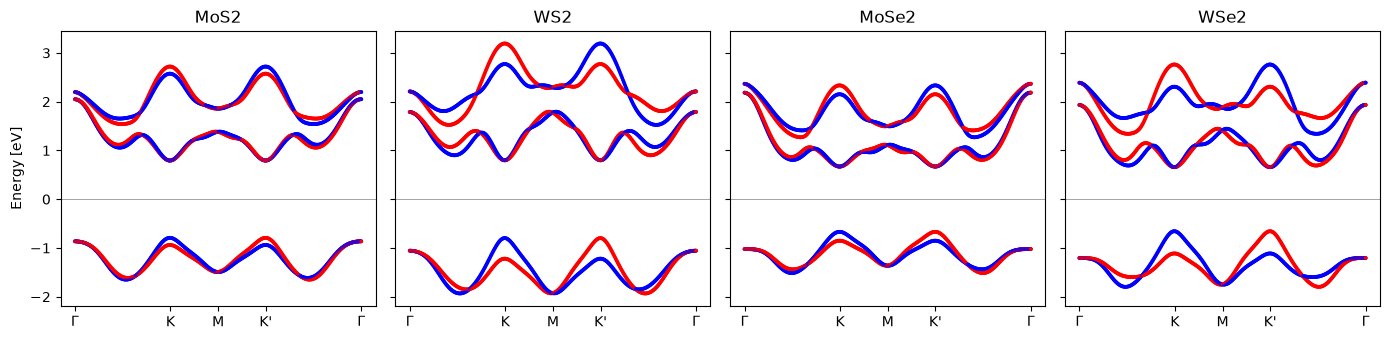

In [2]:
fig,axs = plt.subplots(1,4,figsize=(14,3.5),sharey=True)
for (ax,m) in zip(axs,["MoS2","WS2","MoSe2","WSe2"]):
    h = specialhamiltonian.three_band_tmdc(m) # TNN model, GGA, with SOC
    (k,e,sz) = h.get_bands(operator="sz",write=False)
    ax.scatter(k,e,c=sz,s=3,cmap="bwr",vmin=-1,vmax=1)
    ax.set_xticks([0,k.max()/3,k.max()/2,2*k.max()/3,k.max()])
    ax.set_xticklabels(["$\\Gamma$","K","M","K'","$\\Gamma$"])
    ax.set_title(m) ; ax.axhline(0.,c="gray",lw=0.5)
axs[0].set_ylabel("Energy [eV]")
plt.tight_layout()
plt.show()

The gap is direct, at K and K'. The valence band at K is split by the spin-orbit coupling, much
more in the W compounds than in the Mo ones, and the spin of the upper valence band is opposite
at K and K'. This is the spin-valley locking. Away from the valleys the two spins come together
again, and they are degenerate along $\Gamma$-M, which is a mirror line.

### Spin splitting of the valence band in the Brillouin zone
Since $S_z$ is conserved, we can diagonalize the two spin blocks separately and follow the
splitting $E_{v\uparrow}-E_{v\downarrow}$ of the valence band over the whole Brillouin zone. We do
it for WSe$_2$.

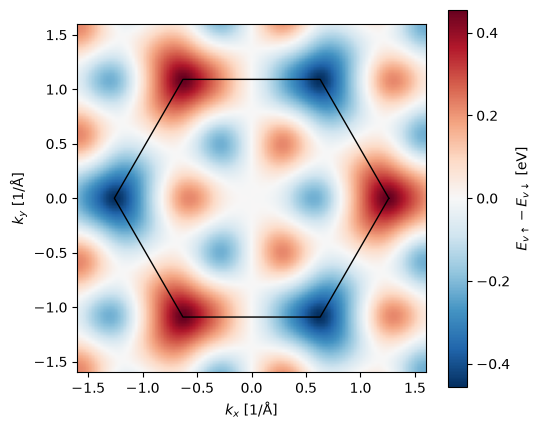

In [3]:
h = specialhamiltonian.three_band_tmdc("WSe2")
hk = h.get_hk_gen()
g = h.geometry
B = 2.*np.pi*np.linalg.inv(np.array([g.a1[:2],g.a2[:2]])).T # reciprocal vectors
up,dn = [0,2,4],[1,3,5] # the basis is (orbital,spin)
kx = np.linspace(-1.6,1.6,121) # Cartesian momenta in 1/A
ky = np.linspace(-1.6,1.6,121)
split = np.zeros((len(ky),len(kx)))
A = np.array([g.a1[:2],g.a2[:2]])
for (i,y) in enumerate(ky):
    for (j,x) in enumerate(kx):
        kr = A@np.array([x,y])/(2.*np.pi) # reduced coordinates
        m = np.asarray(hk([kr[0],kr[1],0.]))
        eu = np.linalg.eigvalsh(m[np.ix_(up,up)])[0] # valence band, spin up
        ed = np.linalg.eigvalsh(m[np.ix_(dn,dn)])[0] # valence band, spin down
        split[i,j] = eu - ed

plt.figure(figsize=(5.5,4.5))
vm = np.max(np.abs(split))
plt.imshow(split,origin="lower",extent=[kx[0],kx[-1],ky[0],ky[-1]],cmap="RdBu_r",
           vmin=-vm,vmax=vm)
plt.colorbar(label="$E_{v\\uparrow}-E_{v\\downarrow}$ [eV]")
K = 4.*np.pi/(3.*np.linalg.norm(g.a1)) # the K points
hexagon = np.array([[K*np.cos(t),K*np.sin(t)] for t in np.linspace(0,2*np.pi,7)])
plt.plot(hexagon[:,0],hexagon[:,1],c="black",lw=1)
plt.xlabel("$k_x$ [1/Å]") ; plt.ylabel("$k_y$ [1/Å]")
plt.tight_layout()
plt.show()

The splitting has opposite signs around K and K', the corners of the hexagon, and it is zero
on the lines from $\Gamma$ to M. It is the valley-contrasting spin splitting that makes the two
valleys addressable with circularly polarized light.

### Comparison with the literature
We compare the gap and the splitting of the valence band at K with Ref. [1].

In [4]:
print("material  gap (eV)  splitting at K (eV)")
for m in ["MoS2","WS2","MoSe2","WSe2","MoTe2","WTe2"]:
    h = specialhamiltonian.three_band_tmdc(m,model="NN") # first-neighbor model
    hk = h.get_hk_gen()
    e = np.linalg.eigvalsh(np.asarray(hk([2./3.,2./3.,0.]))) # at K
    print(m.ljust(9),round(e[2]-e[1],3),"    ",round(e[1]-e[0],3))

material  gap (eV)  splitting at K (eV)
MoS2      1.59      0.146
WS2       1.595      0.422
MoSe2     1.345      0.182
WSe2      1.312      0.456
MoTe2     0.963      0.214
WTe2      0.829      0.474


In this model the valence band at K is a pure $L_z=\pm2$ state, so the splitting is exactly
$2\lambda$. Ref. [1] lists the first-principles splittings $\Delta^v_{\rm SOC}$ = 0.148, 0.430,
0.184, 0.466, 0.215 and 0.486 eV for MoS$_2$, WS$_2$, MoSe$_2$, WSe$_2$, MoTe$_2$ and WTe$_2$
(its Table IV), and fixes $\lambda$ so that $2\lambda$ plus a small second-order correction
reproduces them, which is why the values above are a few meV lower. The gap at K is the one of its
Table I, 1.66 eV for MoS$_2$ in the first-neighbor model, reduced by $\lambda$, since the upper
valence band moves up by $\lambda$ and the conduction band does not move.

[1] G.-B. Liu, W.-Y. Shan, Y. Yao, W. Yao, D. Xiao, *Three-band tight-binding model for
monolayers of group-VIB transition metal dichalcogenides*, Phys. Rev. B **88**, 085433 (2013),
[arXiv:1305.6089](https://arxiv.org/abs/1305.6089)